# FPT — Phân loại tăng/giảm và “chưa đủ tín hiệu”

## Tóm tắt cách đọc
Đối chứng Logistic Regression / XGBoost Classifier với Ridge và baseline. Mỗi classifier có **raw → hiệu chỉnh sigmoid → chọn lọc tín hiệu**. Đọc accuracy cùng **coverage, số calls, coverage tăng/giảm và baseline trên đúng các ngày được chọn**.

**Kết quả lượt này: chưa vượt Ridge.** Mean-fold balanced 2022–2024: Ridge_shared 53,36%, Logistic raw 51,83%, XGBoost raw 49,82%. Sau sigmoid, cả hai classifier đoán giảm toàn bộ 202 phiên năm 2026, balanced 50%; margin 2026 được chọn bằng 0 nên chưa bật vùng bỏ qua. Không sửa ngưỡng theo điểm evaluation.

**Mọi giai đoạn đã được xem trong nghiên cứu trước:** đây là chẩn đoán hồi cứu thích nghi, chưa phải bằng chứng forward. Không thay model serving/API/Streamlit, không commit/push. Notebook chỉ đọc CSV/JSON; không fit hoặc gọi API thị trường.

## Phương pháp và giả định
- Cùng 6 return features; classifier và Ridge_shared học đúng cùng các dòng nonzero trong window 3 năm kết thúc30/6 năm trước. Cấu hình cố định, chưa tìm grid model trên kết quả này.
- Hiệu chỉnh sigmoid dùng July–September năm trước; chọn margin dùng October–December; evaluation năm kế tiếp. Model không refit sau chọn margin. Ridge_recent là control gần hiện tại hơn: train 3 năm đến31/12 năm trước, gồm cả nhãn0, có thêm thông tin gần evaluation; không coi so này là cô lập riêng thuật toán.
- Binary target là tăng/giảm trên phiên return khác0. **Actual0 vẫn giữ trong evaluation**; call vào ngày đó tính sai. Abstain là “chưa đủ tín hiệu”, không được tính đúng class đứng giá. Probability là ước lượng trên mô hình nonzero, không bảo đảm độ tin cậy.
- Ngưỡng: p≥0.5+m ⇒ tăng; p<0.5−m ⇒ giảm; còn lại bỏ qua. Margin chọn trên validation theo balanced accuracy có điều kiện coverage≥60%, ≥30 calls nonzero và ≥10 actual mỗi hướng trong calls; nếu không đủ thì giữ forced coverage100%. Evaluation không được dùng chọn ngưỡng.
- Accuracy calls = số đúng / mọi calls (actual0 tính sai). Hit nonzero = số đúng / calls có actual≠0. Balanced calls chỉ nhìn hai hướng đã gọi; cần đọc coverage từng lớp và correct/all-origins để thấy phần bỏ qua. Xác suất không chuyển thành giá dự báo.
- Primary2022–2024, stress2025/2026 tách riêng; snapshot adjusted Vietcap đến29/10/2026 chưa chứng nhận point-in-time. Không có giai đoạn mới độc lập trong notebook này.

## Dữ liệu và tham số quan sát
Đổi `VIEW_FOLD`/`VIEW_MONTH` trong cell dưới để xem lượt khác, rồi Run all. Chỉ cần numpy/pandas/matplotlib/IPython và thư mục study này; không cần weights. File đã lưu outputs để đọc ngay. Colab cần upload cả thư mục kết quả và đặt `DATA_DIR` nếu không chạy trong repo.

In [1]:
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
VIEW_FOLD = 'eval_2026'
VIEW_MONTH = '2026-10'
DATA_DIR = None
STUDY_ID = '20261030T090621177786Z'
if DATA_DIR is None:
    DATA_DIR=next((p/'reports/direction_selective'/STUDY_ID for p in [Path.cwd(),*Path.cwd().parents]
                   if (p/'reports/direction_selective'/STUDY_ID/'metrics.csv').exists()),None)
if DATA_DIR is None:raise FileNotFoundError('Đặt DATA_DIR tới thư mục chứa metrics.csv và predictions.csv.gz của study.')
DATA_DIR=Path(DATA_DIR)
EXPECTED_SHA256={'metrics.csv': 'd25d251a1588dd140a831fc028c26442b71774bf830043f0b6bfcf37b9f83dc0', 'predictions.csv.gz': '3be6393bddc0f63ed852562477a6ce7ed6d97d185a16212d86897c7f9ebe2d64', 'threshold_selection.csv': '3cce31410712205cf4da0d34a2fce3a48ee4b8e1845eb63807eaa6fea3f5bf74', 'validation_thresholds.csv': 'de34cf118561155b1a97cfddd3499783b5eaff5bb18ce4c64b8232febe2f5f24', 'matched_subset_controls.csv': '2dad26acb3004e0b5cf681504827f3a9eea7fd2816a3f548c1a96599a3f8d823', 'primary_summary.csv': 'bc65f10347a69143bf391b88200d439c51a01607b3b8c828317da204935324ef', 'phase_counts.csv': '67a16fa78fe6e7c2e197c007f961f4c47fb65b805f65f564ff1d24fe4ec21a16', 'diagnostic_2026_slices.csv': '0f12c0356681d505aa88400ff9d83dcb97fa216f05d3dd3cb5bae8098d5699ef', 'protocol.json': '4c1bc89c7a80b1f4241cd92b95ec80aa1c6a33d6eda73d2f56c29ef0eaea45cf', 'verification.json': 'd70b98442c2f627d4bc8b07303b2c232ddd00707cbce6e7bf996ad05de29c8c7', 'probability_diagnostics.csv': '974d75a3a6a23cb6e187a355274ec0f5d8fd2064996c138bcc15af4dcc261222', 'comparison_existing_jun_oct.csv': 'e2884005f0e86e05f9328440fc22cd4ed785ba44d5cdffa20bf4ac097f9db77a'}
for p,sha in EXPECTED_SHA256.items():assert hashlib.sha256((DATA_DIR/p).read_bytes()).hexdigest()==sha,p
read=lambda p:pd.read_csv(DATA_DIR/p)
metrics=read('metrics.csv');primary=read('primary_summary.csv');choices=read('threshold_selection.csv')
probability_diagnostics=read('probability_diagnostics.csv');existing_comparison=read('comparison_existing_jun_oct.csv')
curves=read('validation_thresholds.csv');matched=read('matched_subset_controls.csv')
pred=read('predictions.csv.gz');pred['Date']=pd.to_datetime(pred.Date);pred['Target_Date_1d']=pd.to_datetime(pred.Target_Date_1d)
phase_counts=read('phase_counts.csv');slices=read('diagnostic_2026_slices.csv')
proto=json.loads((DATA_DIR/'protocol.json').read_text());verification=json.loads((DATA_DIR/'verification.json').read_text())
evaluation=pred[pred.phase=='evaluation'].copy()
QA=Path.cwd()/'.cache/direction-notebook-qa';QA.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.figsize':(12,4.5),'font.size':11,'axes.grid':True,'grid.alpha':.18})
def show(name):
    plt.tight_layout();plt.savefig(QA/(name+'.png'),dpi=140,bbox_inches='tight');plt.show()
def table(frame):display(frame.style.format(precision=2,na_rep='—'))
def stats(group):
    y=np.sign(group.actual_log_return.to_numpy());d=group.direction.to_numpy();call=d!=0;correct=call&(d==y)
    up=call&(y>0);down=call&(y<0)
    balanced=50*(np.mean(d[up]>0)+np.mean(d[down]<0)) if up.any() and down.any() else np.nan
    return {'n':len(group),'calls':int(call.sum()),'coverage':100*call.mean(),
            'accuracy':100*correct.sum()/call.sum() if call.any() else np.nan,'balanced':balanced}
for (fold,strategy),g in evaluation.groupby(['fold','strategy']):
    s=stats(g);saved=metrics[(metrics.fold==fold)&(metrics.strategy==strategy)].iloc[0]
    assert s['n']==saved.n and s['calls']==saved.calls_n
    assert np.isclose(s['coverage'],saved.coverage_pct)
    assert np.isclose(s['accuracy'],saved.called_accuracy_all_pct,equal_nan=True)
    assert np.isclose(s['balanced'],saved.balanced_called_nonzero_pct,equal_nan=True)
assert VIEW_FOLD in metrics.fold.unique()
display(Markdown(f"Study **{STUDY_ID}** · {verification['artifacts_reloaded']} artifacts reload · {len(metrics)} metric groups · không train trong notebook."))
table(phase_counts[phase_counts.fold==VIEW_FOLD].set_index('phase')[['n','up_n','down_n','neutral_n','origin_start','target_end']])

Study **20261030T090621177786Z** · 30 artifacts reload · 55 metric groups · không train trong notebook.

,n,up_n,down_n,neutral_n,origin_start,target_end
phase,,,,,,
train_all,746,374,328,44,2022-07-01,2025-06-30
train_direction,702,374,328,0,2022-07-01,2025-06-30
calibration_all,63,27,35,1,2025-07-01,2025-09-30
calibration_direction,62,27,35,0,2025-07-01,2025-09-30
validation,65,29,33,3,2025-10-01,2025-12-31
evaluation,202,80,117,5,2026-01-05,2026-10-29
ridge_recent_train,747,368,342,37,2023-01-03,2025-12-31


## 1. Primary: có tốt hơn qua nhiều năm không?
Các cột là mean riêng từng fold2022–2024; worst-fold giữ trong bảng. Không thêm2025/2026 vào mean để chọn phương án có điểm đẹp. Balanced trên selected calls và coverage là hai đại lượng khác nhau, đều phải đọc.

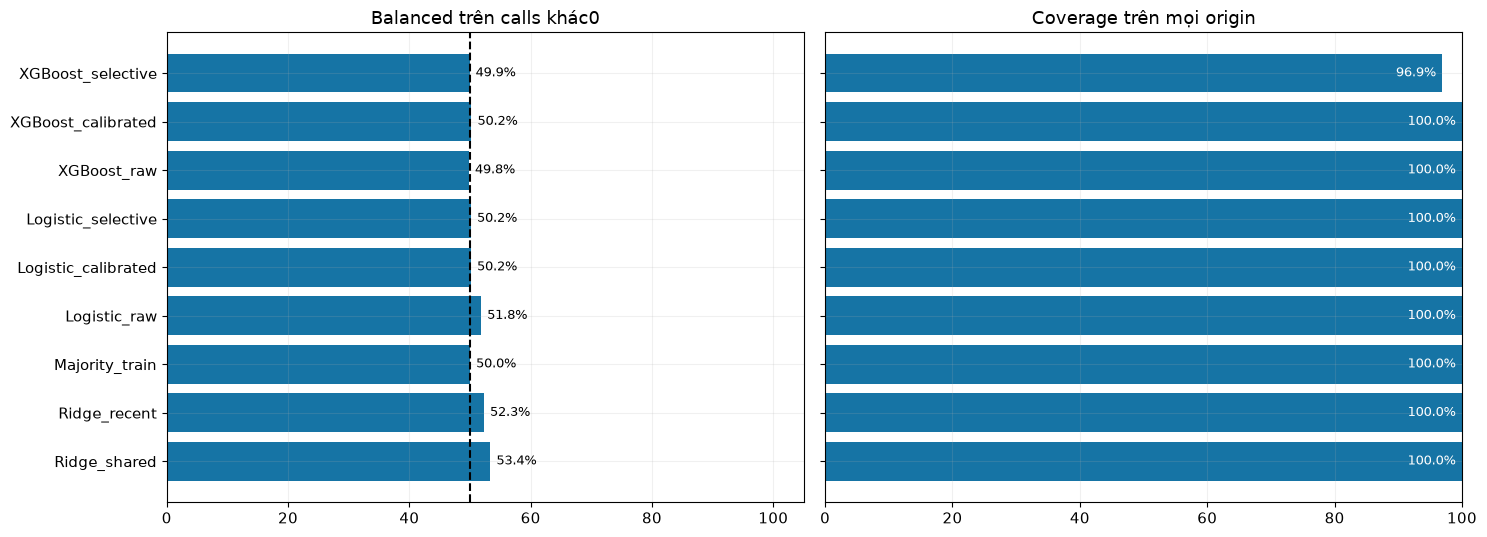

,mean_fold_called_accuracy,mean_fold_balanced,mean_fold_coverage,worst_fold_balanced,mean_fold_brier
strategy,,,,,
Ridge_shared,53.28,53.36,100.00,51.59,—
Ridge_recent,52.21,52.30,100.00,51.03,—
Majority_train,51.41,50.00,100.00,50.00,0.25
Logistic_raw,51.67,51.83,100.00,49.25,0.25
Logistic_calibrated,49.66,50.16,100.00,50.00,0.25
Logistic_selective,49.66,50.16,100.00,50.00,0.25
XGBoost_raw,48.99,49.82,100.00,47.06,0.25
XGBoost_calibrated,49.93,50.24,100.00,49.76,0.25
XGBoost_selective,50.06,49.92,96.91,49.76,0.25


In [2]:
order=['Ridge_shared','Ridge_recent','Majority_train','Logistic_raw','Logistic_calibrated','Logistic_selective','XGBoost_raw','XGBoost_calibrated','XGBoost_selective']
p=primary.set_index('strategy').loc[order]
fig,axes=plt.subplots(1,2,figsize=(15,5.5),sharey=True)
for ax,col,title in [(axes[0],'mean_fold_balanced','Balanced trên calls khác0'),(axes[1],'mean_fold_coverage','Coverage trên mọi origin')]:
    ax.barh(range(len(p)),p[col],color='#1674a5');ax.set_yticks(range(len(p)),p.index);ax.set_xlim(0,105);ax.set_title(title)
    for i,v in enumerate(p[col]):
        if pd.notna(v):ax.text(v-1 if col=='mean_fold_coverage' else v+1,i,f'{v:.1f}%',va='center',fontsize=9,
                              ha='right' if col=='mean_fold_coverage' else 'left',color='white' if col=='mean_fold_coverage' else 'black')
axes[1].set_xlim(0,100)
axes[0].axvline(50,color='black',ls='--');show('01_primary')
table(p[['mean_fold_called_accuracy','mean_fold_balanced','mean_fold_coverage','worst_fold_balanced','mean_fold_brier']])

## 2. Forced và selective trên fold đang xem
Raw/calibrated đều gọi mọi phiên; selective có thể bỏ qua. Đặt số calls/N cạnh coverage. Accuracy conditional cao hơn với ít ngày hơn không tự có nghĩa đã tốt hơn toàn bộ. Actual đứng giá tính sai nếu vẫn gọi tăng/giảm.

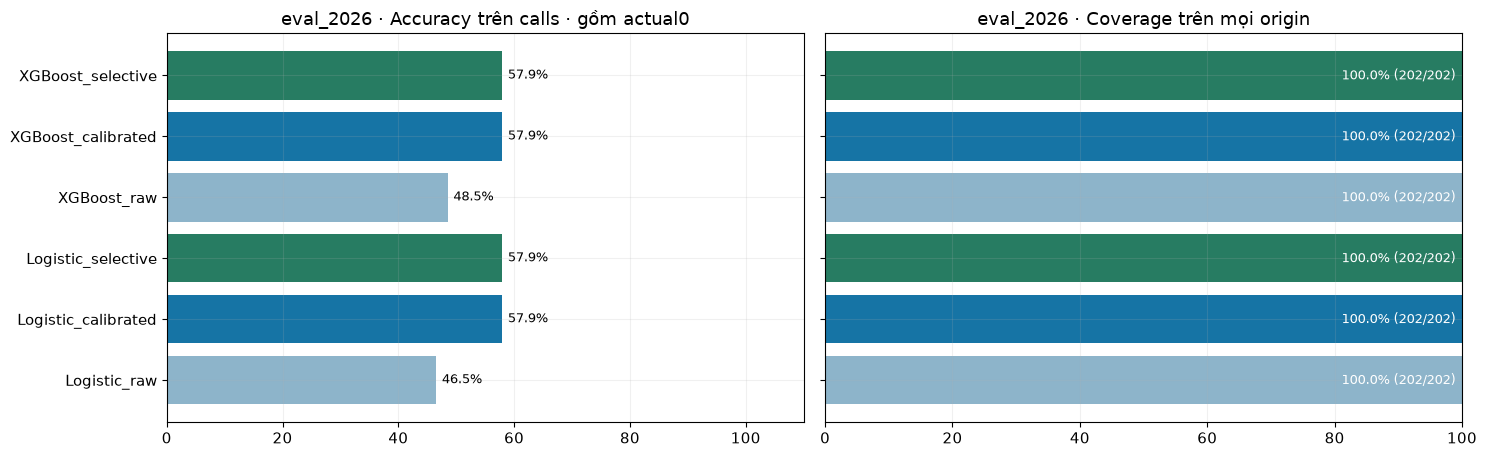

,n,calls_n,abstain_n,called_accuracy_all_pct,hit_nonzero_called_pct,balanced_called_nonzero_pct,up_coverage_pct,down_coverage_pct,correct_over_all_origins_pct
strategy,,,,,,,,,
Ridge_shared,202,202,0,48.02,49.24,53.11,100.00,100.00,48.02
Ridge_recent,202,202,0,49.50,50.76,54.20,100.00,100.00,49.50
Majority_train,202,202,0,39.60,40.61,50.00,100.00,100.00,39.60
Logistic_raw,202,202,0,46.53,47.72,52.82,100.00,100.00,46.53
Logistic_calibrated,202,202,0,57.92,59.39,50.00,100.00,100.00,57.92
Logistic_selective,202,202,0,57.92,59.39,50.00,100.00,100.00,57.92
XGBoost_raw,202,202,0,48.51,49.75,52.36,100.00,100.00,48.51
XGBoost_calibrated,202,202,0,57.92,59.39,50.00,100.00,100.00,57.92
XGBoost_selective,202,202,0,57.92,59.39,50.00,100.00,100.00,57.92


**Logistic:** forced 57.92% / 202 calls; selective 57.92% / 202 calls (100.0% coverage). Chênh accuracy so majority trên cùng calls: CI95% mô tả [6.93; 29.21] điểm %.

**XGBoost:** forced 57.92% / 202 calls; selective 57.92% / 202 calls (100.0% coverage). Chênh accuracy so majority trên cùng calls: CI95% mô tả [6.93; 29.21] điểm %.

In [3]:
view=metrics[metrics.fold==VIEW_FOLD].set_index('strategy')
names=[f'{model}_{mode}' for model in ['Logistic','XGBoost'] for mode in ['raw','calibrated','selective']]
v=view.loc[names];fig,axes=plt.subplots(1,2,figsize=(15,4.7),sharey=True)
for ax,col,title in [(axes[0],'called_accuracy_all_pct','Accuracy trên calls · gồm actual0'),(axes[1],'coverage_pct','Coverage trên mọi origin')]:
    ax.barh(range(len(v)),v[col],color=['#8db4ca','#1674a5','#277c62']*2);ax.set_yticks(range(len(v)),v.index);ax.set_xlim(0,110);ax.set_title(VIEW_FOLD+' · '+title)
    for i,(_,r) in enumerate(v.iterrows()):
        value=r[col]
        if pd.notna(value):
            coverage=col=='coverage_pct'
            ax.text(value-1 if coverage else value+1,i,f'{value:.1f}%'+(f' ({int(r.calls_n)}/{int(r.n)})' if coverage else ''),
                    va='center',fontsize=9,ha='right' if coverage else 'left',color='white' if coverage and value>40 else 'black')
axes[1].set_xlim(0,100);show('02_forced_selective')
table(view.loc[order,['n','calls_n','abstain_n','called_accuracy_all_pct','hit_nonzero_called_pct','balanced_called_nonzero_pct','up_coverage_pct','down_coverage_pct','correct_over_all_origins_pct']])
for model in ['Logistic','XGBoost']:
    forced=view.loc[model+'_calibrated'];selected=view.loc[model+'_selective']
    display(Markdown(f"**{model}:** forced {forced.called_accuracy_all_pct:.2f}% / {int(forced.calls_n)} calls; selective {selected.called_accuracy_all_pct:.2f}% / {int(selected.calls_n)} calls ({selected.coverage_pct:.1f}% coverage). Chênh accuracy so majority trên cùng calls: CI95% mô tả [{selected.hit_delta_majority_ci_low_pp:.2f}; {selected.hit_delta_majority_ci_high_pp:.2f}] điểm %."))

## 3. Vì sao chọn ngưỡng này?
Chỉ các đường **validation** dưới đây được dùng chọn margin. Dấu x là margin đã chọn trước evaluation. Margin0 nghĩa là không có vùng bỏ qua; đây vẫn là kết quả hợp lệ nếu validation chưa ủng hộ việc lọc. Không vẽ rồi chọn lại bằng đường evaluation.

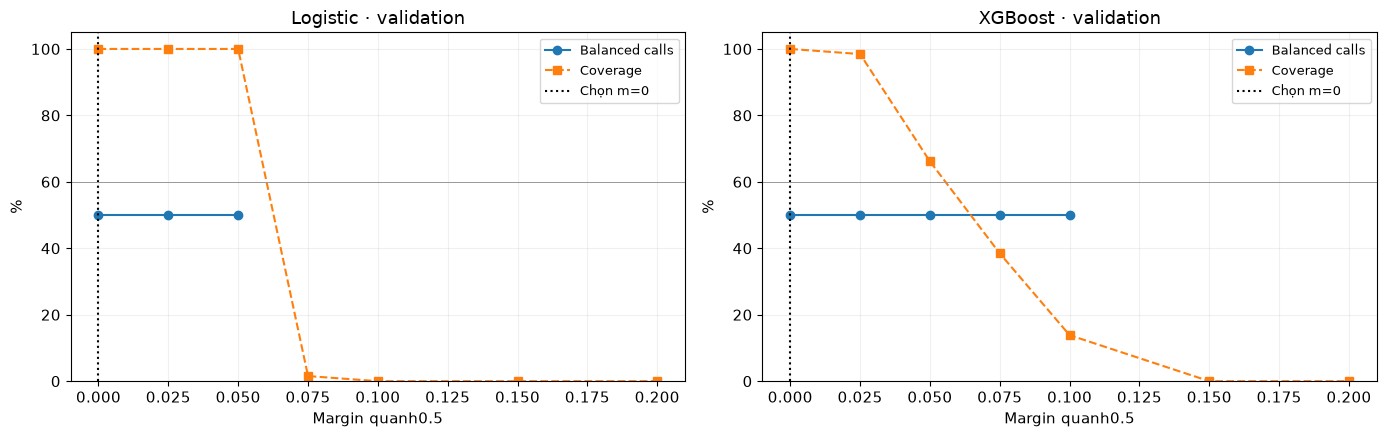

In [4]:
fig,axes=plt.subplots(1,2,figsize=(14,4.5))
for ax,model in zip(axes,['Logistic','XGBoost']):
    g=curves[(curves.fold==VIEW_FOLD)&(curves.model==model)];choice=choices[(choices.fold==VIEW_FOLD)&(choices.model==model)].iloc[0]
    ax.plot(g.margin,g.balanced_called_nonzero_pct,'o-',label='Balanced calls');ax.plot(g.margin,g.coverage_pct,'s--',label='Coverage')
    ax.axvline(choice.margin,color='black',ls=':',label=f'Chọn m={choice.margin:g}');ax.axhline(60,color='#999',lw=.7)
    ax.set_ylim(0,105);ax.set_title(model+' · validation');ax.set_xlabel('Margin quanh0.5');ax.set_ylabel('%');ax.legend(fontsize=9)
show('03_validation_thresholds')
table(choices.set_index(['fold','model'])[['margin','lower_threshold','upper_threshold','reason']])

## 4. Baseline trên đúng những ngày được giữ lại
Cùng calls mask của từng selective model, cho cả Ridge/majority/always-up/down dự đoán. Đây là phép so giúp phân biệt lọc được tín hiệu có ích với chỉ chọn ngày thuận theo lớp chiếm ưu thế. Baseline majority được quyết định từ train, không chọn bằng evaluation.

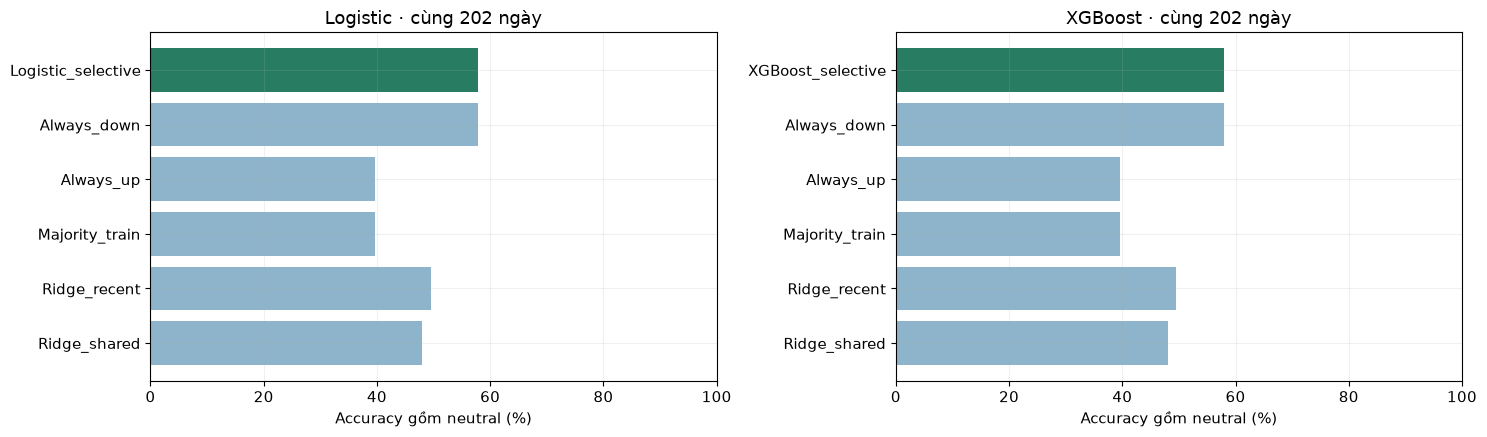

In [5]:
fig,axes=plt.subplots(1,2,figsize=(15,4.5))
for ax,model in zip(axes,['Logistic','XGBoost']):
    g=matched[(matched.fold==VIEW_FOLD)&(matched.selection_strategy==model+'_selective')]
    if g.empty:
        ax.text(.5,.5,'Không có calls',ha='center',transform=ax.transAxes);continue
    ax.barh(g.control,g.called_accuracy_all_pct,color=['#277c62' if x==model+'_selective' else '#8db4ca' for x in g.control]);ax.set_xlim(0,100)
    ax.set_title(f'{model} · cùng {int(g.n.iloc[0])} ngày');ax.set_xlabel('Accuracy gồm neutral (%)')
show('04_matched_controls')
table(matched[matched.fold==VIEW_FOLD].set_index(['selection_strategy','control'])[['n','called_accuracy_all_pct','balanced_called_nonzero_pct']])

## 5. Hiệu chỉnh xác suất có giúp không?
Brier thấp hơn tốt hơn, đo cả chất lượng phân biệt và xác suất; không chỉ riêng calibration. Tính trên **toàn bộ actual khác0**, giữ cùng mẫu raw/calibrated; không chỉ tính những phiên selective chọn. Calibration không tự bảo đảm accuracy tăng.

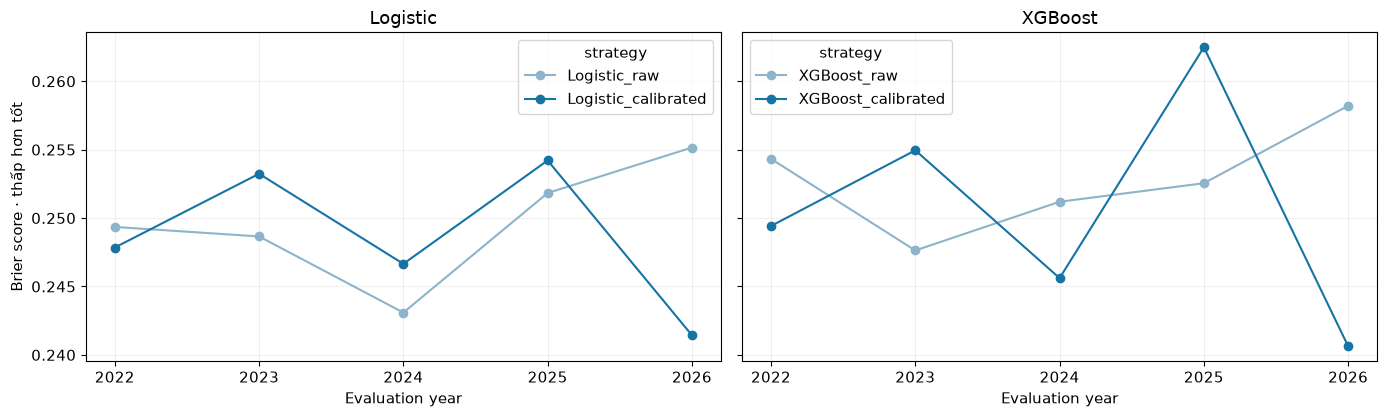

,fold,sigmoid_coef,sigmoid_intercept,calibration_up_pct,evaluation_probability_min,evaluation_probability_max,evaluation_up_calls,evaluation_down_calls,evaluation_n
model,,,,,,,,,
Logistic,eval_2026,0.06,-0.27,43.55,0.42,0.45,0,202,202
XGBoost,eval_2026,0.37,-0.32,43.55,0.38,0.50,0,202,202


Ởfold2026, sigmoid học từ62 nhãn nonzero Q3/2025 (43,55% tăng). P(tăng) sau sigmoid của cả hai đều dưới0,5, nên toàn bộ forecast là giảm. Brier tốt hơn ở2026 nhưng balanced50%: hiệu chỉnh xác suất không tạo thêm tín hiệu phân biệt hướng.

In [6]:
fig,axes=plt.subplots(1,2,figsize=(14,4.3),sharey=True)
for ax,model in zip(axes,['Logistic','XGBoost']):
    g=metrics[metrics.strategy.isin([model+'_raw',model+'_calibrated'])].pivot(index='year',columns='strategy',values='brier_nonzero')
    g=g[[model+'_raw',model+'_calibrated']]
    g.plot(marker='o',ax=ax,color=['#8db4ca','#1674a5']);ax.set_xticks(g.index)
    ax.set_title(model);ax.set_ylabel('Brier score · thấp hơn tốt');ax.set_xlabel('Evaluation year')
show('05_probability_quality')
table(probability_diagnostics[probability_diagnostics.fold==VIEW_FOLD].set_index('model'))
display(Markdown('Ởfold2026, sigmoid học từ62 nhãn nonzero Q3/2025 (43,55% tăng). P(tăng) sau sigmoid của cả hai đều dưới0,5, nên toàn bộ forecast là giảm. Brier tốt hơn ở2026 nhưng balanced50%: hiệu chỉnh xác suất không tạo thêm tín hiệu phân biệt hướng.'))

## 6. Tín hiệu từng ngày trong tháng đang chọn
Đường màu là xác suất tăng sau sigmoid; vùng giữa hai ngưỡng là “chưa đủ tín hiệu”. Chấm actual tăng/giảm ở1/0; actual đứng giá vẽ dấu x ở0.5 **chỉ để hiển thị**, không gán nhãn0.5 hoặc tính abstain là đúng. Nếu đổi fold, chọn tháng thuộc fold đó ở đầu notebook.

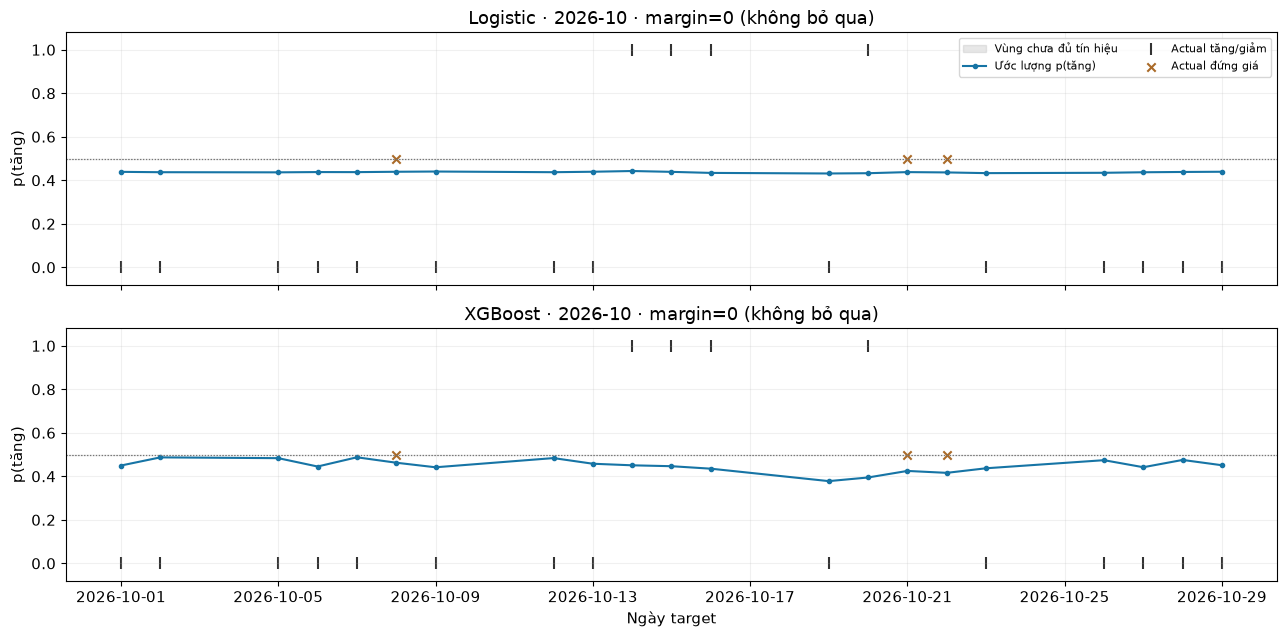

,,probability_up,status,Return thật (%)
Target_Date_1d,strategy,,,
01/10,Logistic_selective,0.44,giam,-0.48
02/10,Logistic_selective,0.44,giam,-0.96
05/10,Logistic_selective,0.44,giam,-0.32
06/10,Logistic_selective,0.44,giam,-2.42
07/10,Logistic_selective,0.44,giam,-1.16
08/10,Logistic_selective,0.44,giam,0.00
09/10,Logistic_selective,0.44,giam,-3.02
12/10,Logistic_selective,0.44,giam,-1.38
13/10,Logistic_selective,0.44,giam,-1.40


In [7]:
month=evaluation[(evaluation.fold==VIEW_FOLD)&(evaluation.Target_Date_1d.dt.strftime('%Y-%m')==VIEW_MONTH)]
assert not month.empty,'Chọn VIEW_MONTH thuộc VIEW_FOLD.'
fig,axes=plt.subplots(2,1,figsize=(13,6.5),sharex=True,sharey=True)
for ax,model in zip(axes,['Logistic','XGBoost']):
    g=month[month.strategy==model+'_selective'];ch=choices[(choices.fold==VIEW_FOLD)&(choices.model==model)].iloc[0]
    ax.axhspan(ch.lower_threshold,ch.upper_threshold,color='#b4b4b4',alpha=.3,label='Vùng chưa đủ tín hiệu')
    ax.plot(g.Target_Date_1d,g.probability_up,'o-',color='#1674a5',ms=3,label='Ước lượng p(tăng)')
    y=np.sign(g.actual_log_return);truth=np.where(y>0,1,np.where(y<0,0,.5))
    nz=y!=0;ax.scatter(g.loc[nz,'Target_Date_1d'],truth[nz],marker='|',s=70,color='#333',label='Actual tăng/giảm')
    ax.scatter(g.loc[~nz,'Target_Date_1d'],truth[~nz],marker='x',color='#aa6a28',label='Actual đứng giá')
    ax.axhline(ch.lower_threshold,color='#777',ls=':',lw=.8);ax.axhline(ch.upper_threshold,color='#777',ls=':',lw=.8)
    ax.set_ylim(-.08,1.08);ax.set_ylabel('p(tăng)');ax.set_title(model+' · '+VIEW_MONTH+f' · margin={ch.margin:g}'+(' (không bỏ qua)' if ch.margin==0 else ''))
axes[0].legend(fontsize=8,ncol=2);axes[-1].set_xlabel('Ngày target');show('06_daily_signals')
daily=month[month.strategy.str.endswith('_selective')][['Target_Date_1d','strategy','actual_log_return','probability_up','status']].copy()
daily['Return thật (%)']=100*np.expm1(daily.pop('actual_log_return'));daily.Target_Date_1d=daily.Target_Date_1d.dt.strftime('%d/%m')
table(daily.set_index(['Target_Date_1d','strategy']))

## 7. Đối chiếu cùng cohort với notebook giá
Full2026, common200 cặp và tháng6–10 common104 cặp không được trộn mẫu số. Bảng này giữ đúng common cohort của Notebook06, chỉ là chẩn đoán; không áp CI full cohort cho subset. So Hit ở đây cần dùng cột nonzero tương ứng với bảng cũ.

In [8]:
table(slices[(slices.scope=='jun_oct_common')&slices.strategy.isin(order)].set_index('strategy')[['n','calls_n','coverage_pct','called_accuracy_all_pct','hit_nonzero_called_pct','balanced_called_nonzero_pct']])
table(existing_comparison[existing_comparison.strategy.isin(['Existing_Ridge_bias_reference','Logistic_raw','XGBoost_raw','Logistic_selective','XGBoost_selective','Always_down'])].set_index('strategy')[['n','calls_n','coverage_pct','hit_nonzero_called_pct','balanced_called_nonzero_pct']])
display(Markdown('Reference bổ sung sau kết quả: Ridge+bias củaNotebook06 trên cùng104 ngày đạt Hit62,63%/balanced57,95%; classifier selective60,61%/50%. Reference không dùng chọn model/ngưỡng lượt mới; provenance giữ riêng.'))
display(Markdown('**Ridge_recent đã được verifier đối chiếu đúng202 forecast với artifact refit_2025_native cũ.** Chênh metric giữa104/200/202 phiên có thể do cohort, không mặc định do model thay đổi.'))

,n,calls_n,coverage_pct,called_accuracy_all_pct,hit_nonzero_called_pct,balanced_called_nonzero_pct
strategy,,,,,,
Logistic_calibrated,104,104,100.00,57.69,60.61,50.00
Logistic_raw,104,104,100.00,41.35,43.43,49.29
Logistic_selective,104,104,100.00,57.69,60.61,50.00
Majority_train,104,104,100.00,37.50,39.39,50.00
Ridge_recent,104,104,100.00,48.08,50.51,55.13
Ridge_shared,104,104,100.00,44.23,46.46,51.35
XGBoost_calibrated,104,104,100.00,57.69,60.61,50.00
XGBoost_raw,104,104,100.00,45.19,47.47,51.28
XGBoost_selective,104,104,100.00,57.69,60.61,50.00


,n,calls_n,coverage_pct,hit_nonzero_called_pct,balanced_called_nonzero_pct
strategy,,,,,
Always_down,104,104,100.00,60.61,50.00
Logistic_raw,104,104,100.00,43.43,49.29
Logistic_selective,104,104,100.00,60.61,50.00
XGBoost_raw,104,104,100.00,47.47,51.28
XGBoost_selective,104,104,100.00,60.61,50.00
Existing_Ridge_bias_reference,104,104,100.00,62.63,57.95


Reference bổ sung sau kết quả: Ridge+bias củaNotebook06 trên cùng104 ngày đạt Hit62,63%/balanced57,95%; classifier selective60,61%/50%. Reference không dùng chọn model/ngưỡng lượt mới; provenance giữ riêng.

**Ridge_recent đã được verifier đối chiếu đúng202 forecast với artifact refit_2025_native cũ.** Chênh metric giữa104/200/202 phiên có thể do cohort, không mặc định do model thay đổi.

## Kết luận để trao đổi với team
- Không chốt selective bằng accuracy cao hơn trên ít ngày. Đọc cùng coverage từng lớp, số calls, correct/all-origins và controls trên đúng các calls đó.
- Nếu validation chọn margin0, giữ kết quả đó: chưa có căn cứ dùng vùng bỏ qua trong fold này. Không chỉnh margin trên2026 để có điểm đẹp.
- Hiệu chỉnh xác suất là một đối chứng riêng, chưa chắc giúp discrimination/accuracy. Model direction không thay phần regression dự báo giá.
- Các giai đoạn đều đã được xem; cần forecast mới ghi trước target để xác nhận forward. Không auto-promotion.

Chi tiết: `REPORT.md`, `protocol.json`, `manifest.json`, `verification.json`, `research_bundle.json` trong thư mục study. Weights ở `models/research/` bị gitignore; notebook đọc kết quả không cần weights. Source/package versions và input ZIP/hash ghi trước training. Không commit/push.